**Eye-Tracking & Neurocognitive Intelligence | Eye-Movement Modelling & Advanced AI | Presented by: Reza Saadatyar (2026)**

**02 | Classical Baselines and Participant-Disjoint Validation**

![Four fixed classical task-classification candidates and the current 100-person evaluation design](../../images/02_statistical_and_classical_ml.svg)

**Objective:** Compare one no-signal class-prior reference and three fixed classical classifiers on the same held-out **Validation recordings**, without inspecting the main Test.

**Current input:** Notebook 01 has already executed on **100 GazeBase Round 1 / Session 1 people**, providing **400 original recordings**, nine record-level features and a frozen **64/16/20 person** Train / Validation / Test split. This notebook will fit models on **256 Train recordings**, assess **64 Validation recordings from 16 independent people**, and leave **80 Test recordings** reserved for Notebook 05.

**Scope:** The four candidates are class prior, class-balanced Logistic Regression, Random Forest and Histogram Gradient Boosting. Imputation and any scaling are fitted within Train only. Each original recording contributes one prediction; record identifiers and participant IDs are excluded from the predictor columns.

**Execution status:** The 100-person classical models **have not yet been executed**. Previously committed 8-record Validation scores belong to the ten-person pilot and must not be reported for the new cohort. This figure describes the current modelling design, not observed 100-person model performance. No Google Drive is required.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_movement_modelling")

# ---------------------------- 2. Data and Models -----------------------------
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from IPython.display import display

# ------------------------ 3. Research Infrastructure -------------------------
from s2_handoff import ensure_s2_stage_inputs, verify_main_cohort
from core.output_download import download_outputs_from_colab
from core.plot_style import plot_style, save_figure
from s2_data import TASKS, CLASS_TO_INDEX, load_protocol
from s2_classical import classical_candidates
from s2_metrics import (
    FEATURE_COLUMN_NAMES, require_split_consistency,
    classical_record_predictions, metric_row,
)

# ----------------------------- 4. Output Context -----------------------------
output_dir = root / "eye_movement_modelling" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Current study outputs:", output_dir)

Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Current study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_movement_modelling/output


**02. Load the Current 100-Person Source Features**

Read `01_record_features.csv`, `01_split_assignments.csv` and `01_protocol.csv` produced by the executed Notebook 01. If a current stage-01 ZIP is explicitly uploaded to `/content/`, its contents take precedence over files in the checkout.

The stage input contract requires **400 unique records**, **100 complete people** and four tasks per person, with **64 Train**, **16 Validation** and **20 reserved Test** people. Source identities and split assignments are verified before any model is fitted. Only the 256 Train and 64 Validation records enter this notebook's modelling operations.

Nine source-derived feature columns are used. The observed source-validity fractions vary across recordings; imputation uses **Train-only medians** and does not imply uniform data quality.


In [3]:
# ======================== 02. Recover Record Features ========================

# ----------------------- 1. Named Current Input Files ------------------------
ensure_s2_stage_inputs(
    output_dir, 1,
    ("01_record_features.csv", "01_split_assignments.csv",
     "01_protocol.csv"),
)
features = pd.read_csv(
    output_dir / "01_record_features.csv",
    dtype={"participant_id": str, "record_id": str},
)
split = pd.read_csv(
    output_dir / "01_split_assignments.csv",
    dtype={"participant_id": str, "record_id": str},
)
protocol = load_protocol(output_dir / "01_protocol.csv")
require_split_consistency(features, split)
role_counts = verify_main_cohort(protocol, split)
print("Main cohort participant roles:", role_counts)

# --------------------- 2. Separate Train and Validation ----------------------
train = features.loc[features.split.eq("train")].copy()
validation = features.loc[features.split.eq("validation")].copy()
feature_names = list(FEATURE_COLUMN_NAMES)
if train.empty or validation.empty:
    raise ValueError("No Train/Validation task records were selected")
print("Protocol purpose:", protocol["purpose"])
print("Train records / participants:", len(train),
      train.participant_id.nunique())
print("Validation records / participants:", len(validation),
      validation.participant_id.nunique())
print("Input feature columns:", feature_names)
display(train[["record_id", "task", "valid_fraction"]].head(8))
candidates = classical_candidates(seed=protocol["split_seed"])
reported = []


Restored Notebook 01 from uploaded ZIP: /content/eye_movement_modelling_Notebook_01_Outputs.zip
Main cohort participant roles: {'train': 64, 'validation': 16, 'test': 20}
Protocol purpose: main
Train records / participants: 256 64
Validation records / participants: 64 16
Input feature columns: ['valid_fraction', 'x_sd_dva', 'y_sd_dva', 'step_median_dva', 'step_p95_dva', 'speed_median_dva_s', 'speed_p95_dva_s', 'pupil_coverage', 'pupil_median_uncalibrated']


,record_id,task,valid_fraction
0,S_1001_S1_FXS,FXS,0.967566
1,S_1001_S1_HSS,HSS,0.996387
2,S_1001_S1_RAN,RAN,0.986779
3,S_1001_S1_TEX,TEX,0.966713
4,S_1002_S1_FXS,FXS,0.968356
5,S_1002_S1_HSS,HSS,0.990959
6,S_1002_S1_RAN,RAN,0.990869
7,S_1002_S1_TEX,TEX,0.985557


**03. Class-Prior Reference**

Fit the fixed `DummyClassifier(strategy="prior")` pipeline on Training records only. It uses class prevalence, not gaze movement, as the no-signal comparator. Score the 64 Validation records once each, then save the fitted pipeline, class probabilities, fixed-label metrics and confusion matrix.

The class-prior score for 100 participants has **not yet been observed**. It must be calculated from this cohort rather than carried over from the pilot.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
0,class_prior,validation,64,16,0.25,0.1,0.25


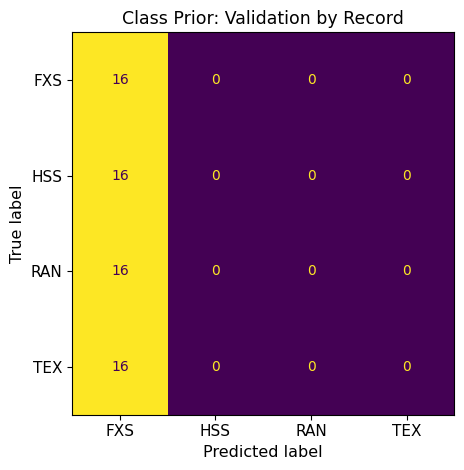

In [4]:
# ==================== 03. No-Signal Class-Prior Baseline =====================

# --------------------------- 1. Fit Train Records ----------------------------
name = "class_prior"
model = candidates[name]
model.fit(train[feature_names], train["task"].map(CLASS_TO_INDEX))
joblib.dump(model, output_dir / f"02_{name}.joblib")

# ---------------------- 2. Evaluate Held-Out Validation ----------------------
pred = classical_record_predictions(
    model, validation, model_name=name, partition="validation",
)
pred.to_csv(output_dir / f"02_{name}_validation_predictions.csv", index=False)
row = metric_row(
    pred.target_index, pred.pred_index, model=name,
    partition="validation",
    n_participants=validation["participant_id"].nunique(),
)
reported.append(row)
display(pd.DataFrame([row]))

# ---------------------- 3. Display Model Error Pattern -----------------------
matrix = confusion_matrix(
    pred.target_index, pred.pred_index, labels=range(len(TASKS)),
)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=ax, colorbar=False, values_format="d",
)
ax.set_title("Class Prior: Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"02_{name}_confusion.png")
plt.show()


**04. Logistic Regression**

Fit the existing class-balanced Logistic Regression pipeline on the same 256 Train recordings. Its median imputer and standard scaler are fitted inside the Training pipeline, and no participant ID, source filename or Test field enters its predictors.

Evaluate the fitted model on all 64 Validation recordings, saving the four-class probabilities, record-level accuracy, Macro F1, balanced accuracy and confusion matrix. Hyperparameters remain unchanged from the approved pilot.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
0,logistic_regression,validation,64,16,1.0,1.0,1.0


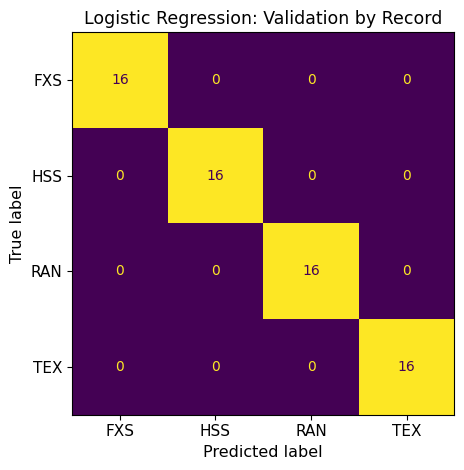

In [5]:
# ======================= 04. Logistic Regression Model =======================

# --------------------------- 1. Fit Train Records ----------------------------
name = "logistic_regression"
model = candidates[name]
model.fit(train[feature_names], train["task"].map(CLASS_TO_INDEX))
joblib.dump(model, output_dir / f"02_{name}.joblib")

# ---------------------- 2. Evaluate Held-Out Validation ----------------------
pred = classical_record_predictions(
    model, validation, model_name=name, partition="validation",
)
pred.to_csv(output_dir / f"02_{name}_validation_predictions.csv", index=False)
row = metric_row(
    pred.target_index, pred.pred_index, model=name,
    partition="validation",
    n_participants=validation["participant_id"].nunique(),
)
reported.append(row)
display(pd.DataFrame([row]))

# ---------------------- 3. Display Model Error Pattern -----------------------
matrix = confusion_matrix(
    pred.target_index, pred.pred_index, labels=range(len(TASKS)),
)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=ax, colorbar=False, values_format="d",
)
ax.set_title("Logistic Regression: Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"02_{name}_confusion.png")
plt.show()


**05. Random Forest**

Fit the fixed 120-tree, depth-limited Random Forest with Training-only median imputation. Compare predictions against the **same 16 Validation people and 64 source recordings** used by Logistic Regression and the class prior.

Store its fitted pipeline, probabilities, fixed-label metrics and confusion matrix. No main-Test labels or model-selection feedback are used.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
0,random_forest,validation,64,16,0.984375,0.98436,0.984375


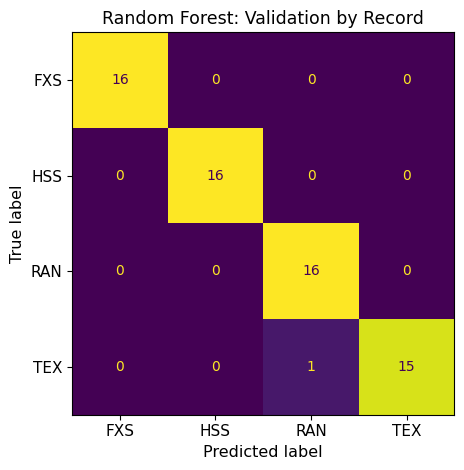

In [6]:
# ========================== 05. Random Forest Model ==========================

# --------------------------- 1. Fit Train Records ----------------------------
name = "random_forest"
model = candidates[name]
model.fit(train[feature_names], train["task"].map(CLASS_TO_INDEX))
joblib.dump(model, output_dir / f"02_{name}.joblib")

# ---------------------- 2. Evaluate Held-Out Validation ----------------------
pred = classical_record_predictions(
    model, validation, model_name=name, partition="validation",
)
pred.to_csv(output_dir / f"02_{name}_validation_predictions.csv", index=False)
row = metric_row(
    pred.target_index, pred.pred_index, model=name,
    partition="validation",
    n_participants=validation["participant_id"].nunique(),
)
reported.append(row)
display(pd.DataFrame([row]))

# ---------------------- 3. Display Model Error Pattern -----------------------
matrix = confusion_matrix(
    pred.target_index, pred.pred_index, labels=range(len(TASKS)),
)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=ax, colorbar=False, values_format="d",
)
ax.set_title("Random Forest: Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"02_{name}_confusion.png")
plt.show()


**06. Gradient Boosting**

Fit the approved regularised Histogram Gradient Boosting model with 65 maximum iterations and Training-only median imputation. Its configuration remains unchanged; only the source cohort is larger.

Save one probability vector and one predicted class for each original Validation recording, alongside the confusion matrix and comparable metric row. Any performance differences must be interpreted in the context of the original GazeBase task protocols, not cognitive outcomes.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
0,gradient_boosting,validation,64,16,0.984375,0.98436,0.984375


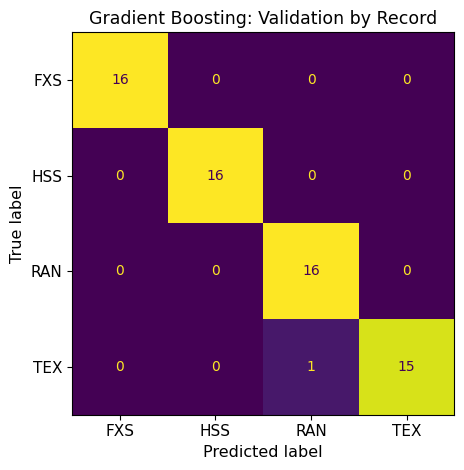

In [7]:
# ======================== 06. Gradient Boosting Model ========================

# --------------------------- 1. Fit Train Records ----------------------------
name = "gradient_boosting"
model = candidates[name]
model.fit(train[feature_names], train["task"].map(CLASS_TO_INDEX))
joblib.dump(model, output_dir / f"02_{name}.joblib")

# ---------------------- 2. Evaluate Held-Out Validation ----------------------
pred = classical_record_predictions(
    model, validation, model_name=name, partition="validation",
)
pred.to_csv(output_dir / f"02_{name}_validation_predictions.csv", index=False)
row = metric_row(
    pred.target_index, pred.pred_index, model=name,
    partition="validation",
    n_participants=validation["participant_id"].nunique(),
)
reported.append(row)
display(pd.DataFrame([row]))

# ---------------------- 3. Display Model Error Pattern -----------------------
matrix = confusion_matrix(
    pred.target_index, pred.pred_index, labels=range(len(TASKS)),
)
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ConfusionMatrixDisplay(matrix, display_labels=TASKS).plot(
    ax=ax, colorbar=False, values_format="d",
)
ax.set_title("Gradient Boosting: Validation by Record")
fig.tight_layout()
save_figure(fig, output_dir / f"02_{name}_confusion.png")
plt.show()


**07. Compare Classical Models on Common Validation Recordings**

The model table will contain **four candidates**, all scored on the identical 64 Validation recordings. The primary reported development metrics are fixed-class **Macro F1**, **balanced accuracy** and **accuracy**. The comparison figure is generated from the newly observed values and saved as `02_classical_comparison.png`.

No model has been selected using the main Test. These are Validation diagnostics for the subsequent comparison with CNN, TCN, GRU and Transformer, not a final Test estimate or proof of generalisation across sessions or devices.


,model,partition,n_records,n_participants,accuracy,macro_f1,balanced_accuracy
1,logistic_regression,validation,64,16,1.000000,1.00000,1.000000
3,gradient_boosting,validation,64,16,0.984375,0.98436,0.984375
2,random_forest,validation,64,16,0.984375,0.98436,0.984375
0,class_prior,validation,64,16,0.250000,0.10000,0.250000


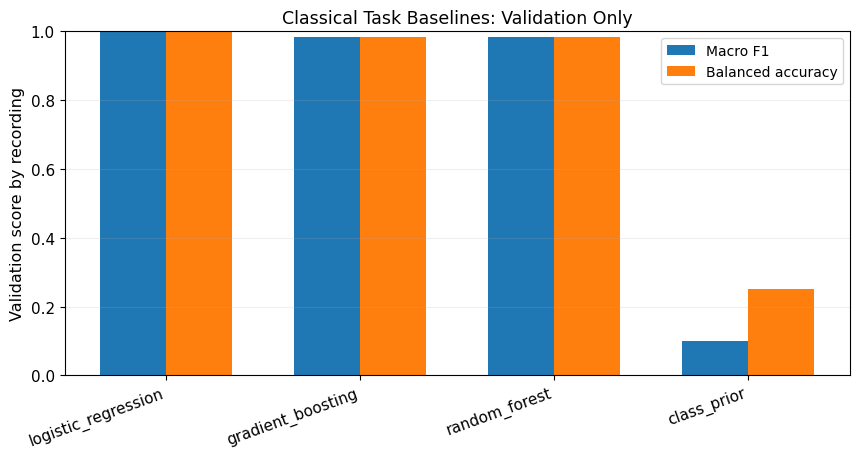

In [8]:
# ===================== 07. Compare Classical Validation ======================

# ----------------------- 1. Persist Comparable Scores ------------------------
metrics = pd.DataFrame(reported).sort_values(
    ["macro_f1", "balanced_accuracy", "model"],
    ascending=[False, False, True],
)
metrics.to_csv(output_dir / "02_validation_metrics.csv", index=False)
display(metrics)

# ------------------------ 2. Plot Record-Level Scores ------------------------
fig, ax = plt.subplots(figsize=(8.7, 4.7))
positions = np.arange(len(metrics))
ax.bar(positions - 0.17, metrics["macro_f1"], width=0.34,
       label="Macro F1")
ax.bar(positions + 0.17, metrics["balanced_accuracy"], width=0.34,
       label="Balanced accuracy")
ax.set_xticks(positions, metrics["model"], rotation=20, ha="right")
ax.set(ylabel="Validation score by recording",
       ylim=(0, 1), title="Classical Task Baselines: Validation Only")
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
save_figure(fig, output_dir / "02_classical_comparison.png")
plt.show()


**08. Check Saved Results and Export Stage 02**

Before packaging, check that all four current-cohort prediction tables refer to **exactly the 64 original Validation records**, preserve the expected task labels and have a corresponding saved model, confusion matrix and metrics row. This prevents a partially rerun stage from silently packaging old pilot predictions.

The stage-owned ZIP contains **14 files**: four fitted pipelines, four source-level Validation prediction tables, four confusion figures, one combined metrics CSV and one comparison plot. Download `eye_movement_modelling_Notebook_02_Outputs.zip` before ending Colab; Notebook 05 will later consume these Validation metrics and saved models. Notebook 03 can use the already prepared stage-01 windows independently.


In [ ]:
# ================== 08. Verify and Export Stage-02 Evidence ==================

# ----------------------- 1. Confirm All Expected Files -----------------------
model_names = (
    "class_prior", "logistic_regression",
    "random_forest", "gradient_boosting",
)
required_stage02 = [
    "02_validation_metrics.csv",
    "02_classical_comparison.png",
]
for model_name in model_names:
    required_stage02.extend((
        f"02_{model_name}.joblib",
        f"02_{model_name}_validation_predictions.csv",
        f"02_{model_name}_confusion.png",
    ))
missing_stage02 = [
    name for name in required_stage02
    if not (output_dir / name).is_file()
]
if missing_stage02:
    raise FileNotFoundError(
        f"Stage 02 is incomplete: {missing_stage02}"
    )

# --------------- 2. Verify Current Validation Source Identity ----------------
expected_ids = set(validation.record_id.astype(str))
expected_labels = validation.set_index("record_id")["task"].map(
    CLASS_TO_INDEX
)
saved_scores = pd.read_csv(output_dir / "02_validation_metrics.csv")
if (
    len(saved_scores) != len(model_names)
    or set(saved_scores.model) != set(model_names)
    or not saved_scores.partition.eq("validation").all()
):
    raise ValueError("Stage-02 metric rows do not cover the four candidates")

for model_name in model_names:
    saved = pd.read_csv(
        output_dir / f"02_{model_name}_validation_predictions.csv",
        dtype={"record_id": str, "participant_id": str},
    )
    if (
        saved.record_id.duplicated().any()
        or set(saved.record_id) != expected_ids
        or not saved.partition.eq("validation").all()
    ):
        raise ValueError(
            f"{model_name} predictions do not match the current "
            "Validation source records"
        )
    observed_targets = saved.set_index("record_id").target_index
    if not observed_targets.sort_index().equals(
        expected_labels.sort_index()
    ):
        raise ValueError(
            f"{model_name} Validation targets differ from Notebook 01"
        )
    row = saved_scores.loc[saved_scores.model.eq(model_name)].iloc[0]
    if (
        int(row.n_records) != len(saved)
        or int(row.n_participants)
        != validation.participant_id.nunique()
    ):
        raise ValueError(
            f"{model_name} Validation metric denominators are inconsistent"
        )

print("Verified four models against current 64-record Validation registry.")

# -------------------------- 3. Export One Stage ZIP --------------------------
download_outputs_from_colab("eye_movement_modelling/output", "02")


Verified four models against current 64-record Validation registry.
------------------------------------------------------------------------
Notebook 02
Files packaged: 14
  + 02_class_prior.joblib
  + 02_class_prior_confusion.png
  + 02_class_prior_validation_predictions.csv
  + 02_classical_comparison.png
  + 02_gradient_boosting.joblib
  + 02_gradient_boosting_confusion.png
  + 02_gradient_boosting_validation_predictions.csv
  + 02_logistic_regression.joblib
  + 02_logistic_regression_confusion.png
  + 02_logistic_regression_validation_predictions.csv
  + 02_random_forest.joblib
  + 02_random_forest_confusion.png
  + 02_random_forest_validation_predictions.csv
  + 02_validation_metrics.csv
Download ZIP from Colab Contents: /content/eye_movement_modelling_Notebook_02_Outputs.zip
